# Cash Radar — spotting a cash shortage before it happens

**Question:** a fictional French furniture maker, *Atelier Verde SAS*, is profitable on paper.
Will it have enough cash for the next 13 weeks — and what happens if its biggest customer pays late?

This notebook walks through the full analysis behind the Cash Radar feature:

1. The data and the profit-vs-cash problem
2. Customer payment habits
3. The 13-week forecast
4. Uncertainty (a likely range, not one number)
5. A delayed-payment scenario and the warning it produces
6. Actions the CFO could take
7. How accurate the method is (backtest)

> All company data is **fictional** and simulated (see `scripts/`). French payment rules and Banque de France
> statistics were used to make it realistic.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cash_radar as cr

FIG = pathlib.Path.cwd().parent / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 10})
GREEN, RED, ORANGE, GREY, BLUE = "#1f6e54", "#c0392b", "#e08a1e", "#8b918d", "#2f6db5"
eur = lambda v: f"{'−' if v < 0 else ''}€{abs(v):,.0f}"
kfmt = plt.FuncFormatter(lambda v, _: f"{'−' if v < 0 else ''}€{abs(v)/1000:,.0f}k")

ds = cr.load()
s = ds.settings
print(s)

Settings(as_of=datetime.date(2026, 10, 9), forecast_start=datetime.date(2026, 10, 12), opening_balance=381240.65, buffer=100000.0, overdraft_limit=150000.0, weeks=13, lookback_days=365, company='Atelier Verde SAS (fictional)')


## 1. The data

In [2]:
pd.DataFrame({name: [len(getattr(ds, name))] for name in
              ["customers", "invoices", "orders", "planned_payments", "bank_transactions"]}, index=["rows"]).T

,rows
customers,12
invoices,1210
orders,194
planned_payments,72
bank_transactions,1416


In [3]:
ds.customers

,customer_id,customer_name,segment,country,payment_terms_days,payment_method
0,C01,Lumen Hospitality Group,Hospitality (projects),FR,60,Bank transfer
1,C02,Bâtir Bureaux SAS,Office fit-out contractor,FR,60,Bank transfer
2,C03,Espace & Co Aménagement,Office fit-out contractor,FR,60,Bank transfer
3,C04,Nova Interiors SARL,Office fit-out contractor,FR,45,Bank transfer
4,C05,Officea Distribution,Furniture distributor,FR,45,LCR (bill of exchange)
5,C06,Mobilier Pro Rhône,Furniture distributor,FR,45,Bank transfer
6,C07,Studio Kaya Design,Office fit-out contractor,FR,30,Bank transfer
7,C08,Université Lyon-Est,Public sector,FR,30,Bank transfer (Chorus Pro)
8,C09,CHU Vallée du Rhône,Public sector (hospital),FR,50,Bank transfer (Chorus Pro)
9,C10,Azur Collection Hôtels,Hospitality (projects),FR,45,Bank transfer


### Profit is not cash

Over a year the company is profitable (about €190k net profit expected in 2026), even if quiet months like August
lose money. But the bank balance swings by hundreds of thousands of euros, because customers pay 45–60 days (or more)
after the invoice, while salaries, VAT and timber are paid on fixed dates. In summer 2025 the company went into its
overdraft without seeing it coming, and in November 2025 cash fell to almost zero.

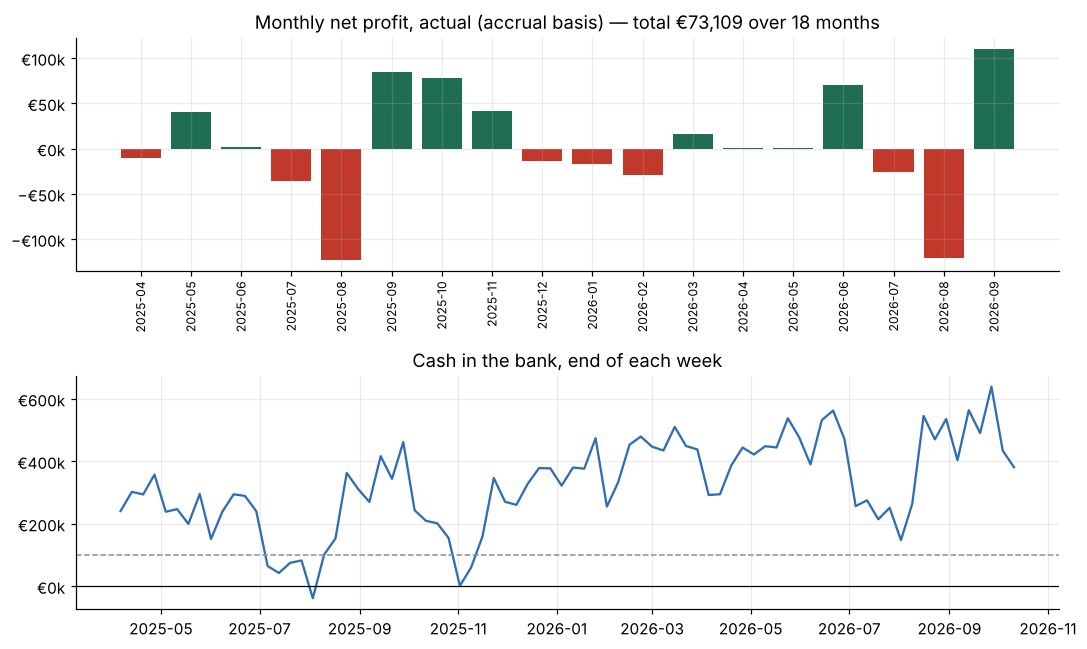

Lowest weekly balance in history: −€38,211 on 2025-08-03


In [4]:
pnl = pd.read_csv(cr.data.SAMPLE_DIR / "profit_and_loss_monthly.csv")
pnl = pnl[pnl.basis == "Actual"]
bal = cr.engine.balance_history(ds.bank_transactions, s)
weekly_bal = bal.resample("W-SUN").last()

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=False)
ax[0].bar(pnl.month, pnl.net_profit, color=[GREEN if v >= 0 else RED for v in pnl.net_profit])
ax[0].set_title(f"Monthly net profit, actual (accrual basis) — total {eur(pnl.net_profit.sum())} over {len(pnl)} months"); ax[0].yaxis.set_major_formatter(kfmt)
ax[0].tick_params(axis="x", rotation=90, labelsize=8)
ax[1].plot(weekly_bal.index, weekly_bal.values, color=BLUE)
ax[1].axhline(s.buffer, color=GREY, ls="--", lw=1); ax[1].axhline(0, color="black", lw=.8)
ax[1].set_title("Cash in the bank, end of each week"); ax[1].yaxis.set_major_formatter(kfmt)
plt.tight_layout(); plt.savefig(FIG / "profit_vs_cash.png", bbox_inches="tight"); plt.show()
print("Lowest weekly balance in history:", eur(weekly_bal.min()), "on", weekly_bal.idxmin().date())

## 2. Customer payment habits

Customers rarely pay on the due date. For each customer we take the **median days late** over the last 12 months.
A customer whose last 90 days are 7+ days slower than usual is flagged.

In [5]:
habits = cr.habit_table(ds.invoices, ds.customers, s.as_of)
habits.sort_values("usual_days_late", ascending=False)

,customer_id,customer_name,segment,payment_terms_days,invoices_paid_12m,usual_days_late,recent_days_late_90d,slowing
3,C04,Nova Interiors SARL,Office fit-out contractor,45,65,25.0,34.941176,True
8,C09,CHU Vallée du Rhône,Public sector (hospital),50,26,23.5,27.571429,False
1,C02,Bâtir Bureaux SAS,Office fit-out contractor,60,70,21.0,23.550000,False
0,C01,Lumen Hospitality Group,Hospitality (projects),60,3,13.0,11.000000,False
10,C11,Hub & Desk Coworking SAS,Direct corporate client,30,49,12.0,10.272727,False
9,C10,Azur Collection Hôtels,Hospitality (projects),45,3,11.0,NaN,False
2,C03,Espace & Co Aménagement,Office fit-out contractor,60,62,10.0,12.266667,False
7,C08,Université Lyon-Est,Public sector,30,24,8.5,13.000000,False
5,C06,Mobilier Pro Rhône,Furniture distributor,45,114,7.0,8.296296,False
11,C12,Arkade Interiors SRL,Export distributor,60,41,6.0,6.222222,False


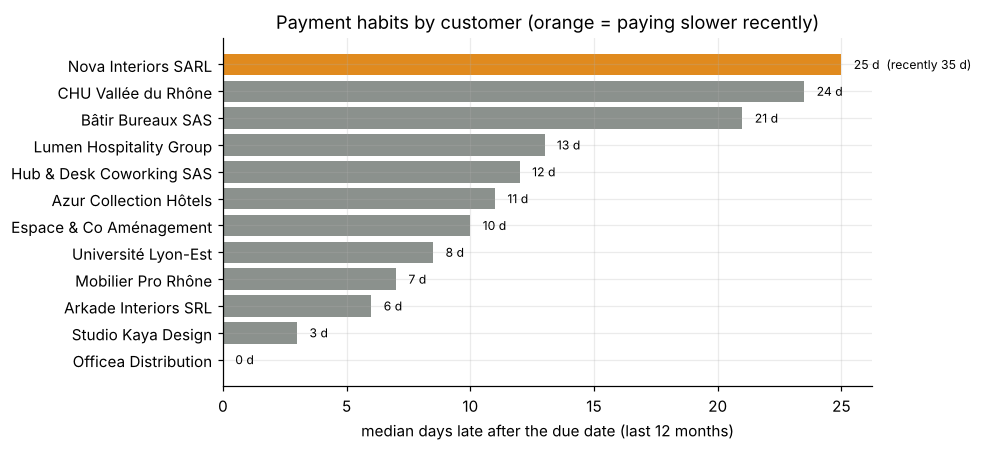

In [6]:
h = habits.sort_values("usual_days_late")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(h.customer_name, h.usual_days_late, color=[ORANGE if x else GREY for x in h.slowing])
for y, (v, r) in enumerate(zip(h.usual_days_late, h.recent_days_late_90d)):
    ax.text(v + .5, y, f"{v:.0f} d" + (f"  (recently {r:.0f} d)" if not np.isnan(r) and r > v + 7 else ""), va="center", fontsize=8)
ax.set_xlabel("median days late after the due date (last 12 months)")
ax.set_title("Payment habits by customer (orange = paying slower recently)")
plt.tight_layout(); plt.savefig(FIG / "customer_habits.png", bbox_inches="tight"); plt.show()

## 3. The 13-week forecast

Every open invoice and confirmed order becomes an expected receipt on *due date + usual delay*; every bill, salary,
tax and loan payment is placed on its own date. Disputed invoices are left out until they are settled.

In [7]:
lines = cr.build_lines(ds.invoices, ds.orders, ds.planned_payments, ds.customers, s)
print(len(lines), "forecast lines;", (~lines.included).sum(), "excluded (disputed)")
lines.drop(columns="samples").head(8)

374 forecast lines; 2 excluded (disputed)


,source,source_id,flow,category,counterparty,customer_id,amount,probability,due_date,days_late_now,assumed_days_late,expected_date,status,included,deferrable,uncertainty_pct,description,expected_value,week
0,invoice,INV-2026-1066,receipt,Customers – Office fit-out contractor,Nova Interiors SARL,C04,15432.0,1.0,2026-09-03,36,49.0,2026-10-22,disputed,False,False,0.0,Furniture order,15432.0,2
1,invoice,INV-2026-1068,receipt,Customers – Office fit-out contractor,Bâtir Bureaux SAS,C02,14868.0,1.0,2026-09-18,21,30.0,2026-10-19,open,True,False,0.0,Furniture order,14868.0,2
2,invoice,INV-2026-1085,receipt,Customers – Office fit-out contractor,Bâtir Bureaux SAS,C02,15720.0,1.0,2026-09-29,10,24.0,2026-10-23,open,True,False,0.0,Furniture order,15720.0,2
3,invoice,INV-2026-1087,receipt,Customers – Office fit-out contractor,Bâtir Bureaux SAS,C02,7836.0,1.0,2026-10-02,7,23.0,2026-10-26,open,True,False,0.0,Furniture order,7836.0,3
4,invoice,INV-2026-1093,receipt,Customers – Export distributor,Arkade Interiors SRL,C12,10400.0,1.0,2026-10-06,3,8.0,2026-10-14,open,True,False,0.0,Furniture order,10400.0,1
5,invoice,INV-2026-1094,receipt,Customers – Export distributor,Arkade Interiors SRL,C12,10630.0,1.0,2026-10-06,3,8.0,2026-10-14,open,True,False,0.0,Furniture order,10630.0,1
6,invoice,INV-2026-1101,receipt,Customers – Office fit-out contractor,Nova Interiors SARL,C04,15624.0,1.0,2026-09-21,18,28.0,2026-10-19,open,True,False,0.0,Furniture order,15624.0,2
7,invoice,INV-2026-1102,receipt,Customers – Office fit-out contractor,Bâtir Bureaux SAS,C02,18648.0,1.0,2026-10-06,3,21.0,2026-10-27,open,True,False,0.0,Furniture order,18648.0,3


In [8]:
base = cr.weekly(lines, s)
base.style.format({c: "€{:,.0f}" for c in ["opening", "receipts", "payments", "net", "closing"]})

,week,week_start,opening,receipts,payments,net,closing,below_buffer,status
0,1,2026-10-12,"€381,241","€43,422","€-141,822","€-98,400","€282,840",False,ok
1,2,2026-10-19,"€282,840","€177,048","€-10,712","€166,336","€449,177",False,ok
2,3,2026-10-26,"€449,177","€90,984","€-439,304","€-348,320","€100,857",False,ok
3,4,2026-11-02,"€100,857","€147,432","€-77,498","€69,934","€170,791",False,ok
4,5,2026-11-09,"€170,791","€112,196","€-29,012","€83,184","€253,975",False,ok
5,6,2026-11-16,"€253,975","€155,832","€-291,170","€-135,338","€118,637",False,ok
6,7,2026-11-23,"€118,637","€391,012","€-166,272","€224,740","€343,376",False,ok
7,8,2026-11-30,"€343,376","€100,634","€-279,685","€-179,051","€164,325",False,ok
8,9,2026-12-07,"€164,325","€145,490","€-91,115","€54,375","€218,701",False,ok
9,10,2026-12-14,"€218,701","€212,784","€-160,224","€52,560","€271,260",False,ok


## 4. Uncertainty

The forecast is repeated 4,000 times, each time drawing every invoice's delay from that customer's past delays.
This gives a likely range (P10–P90: 8 futures out of 10) and the chance of falling below the €100k minimum.

In [9]:
sims = cr.simulate(lines, s, n=4000)
b0 = cr.bands(sims, s)
print(f"Chance of at least one week below the minimum: {(sims.min(axis=1) < s.buffer).mean():.0%}")
b0.style.format({"p10": "€{:,.0f}", "p50": "€{:,.0f}", "p90": "€{:,.0f}", "p_below_buffer": "{:.0%}", "p_overdraft": "{:.0%}"})

Chance of at least one week below the minimum: 40%


,week,p10,p50,p90,p_below_buffer,p_overdraft
0,1,"€312,708","€341,561","€378,223",0%,0%
1,2,"€421,505","€459,515","€505,876",0%,0%
2,3,"€78,240","€125,905","€171,788",25%,0%
3,4,"€131,307","€182,531","€228,454",2%,0%
4,5,"€249,962","€299,356","€352,090",0%,0%
5,6,"€100,091","€152,279","€204,503",10%,0%
6,7,"€301,419","€353,161","€399,923",0%,0%
7,8,"€168,347","€218,833","€264,173",0%,0%
8,9,"€215,294","€263,580","€313,844",0%,0%
9,10,"€245,933","€314,669","€437,354",0%,0%


## 5. What if the biggest customer pays late?

Scenario: **Lumen Hospitality pays its €230k invoice 45 days later than usual.**

In [10]:
sc = cr.Scenario("Lumen pays 45 days late", customer_delay={"C01": 45})
lines_sc = cr.apply_scenario(lines, s, sc)
scen = cr.weekly(lines_sc, s)
sims_sc = cr.simulate(lines, s, sc, n=4000)
b1 = cr.bands(sims_sc, s)
wn = cr.warning(base, scen, lines, lines_sc, sims_sc, s, sc.name)
print(cr.warning_text(wn, ds.profit_for_period))

Cash falls below the buffer in week 8 (week of 30 Nov 2026) and reaches −€66,075 in week 8, €166,075 below the buffer, into the overdraft. Main cause: Lumen Hospitality Group's €230,400 payment moves from week 7 to after the horizon. Large payments that week: Holzwerk Bayern GmbH €122,068, Employees (38 FTE) €106,000, Aciers Rhône-Métal €38,640. You have 7 weeks to act. A shortfall happens in 100% of simulations. Profit for the period is still €182,318: this is a timing problem, not a profit problem.


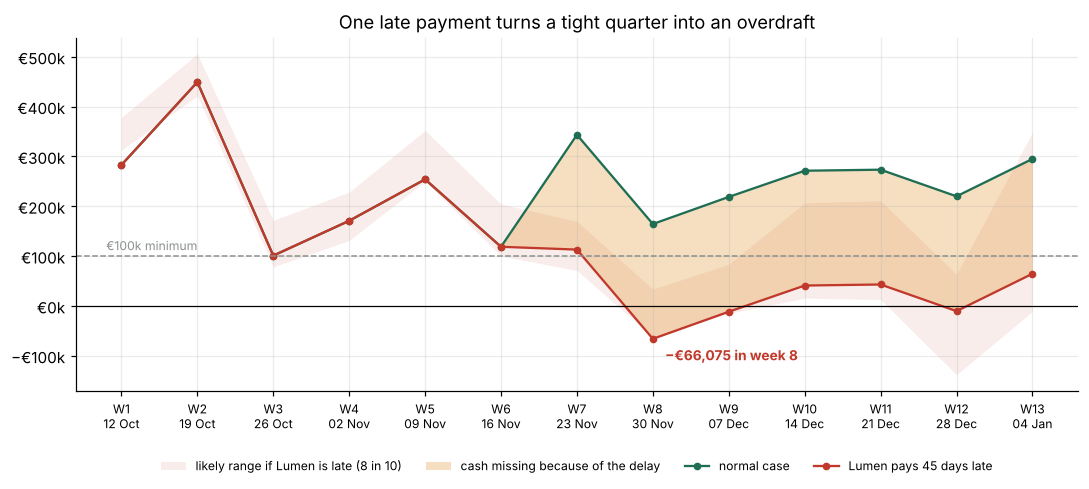

In [11]:
x = np.arange(1, s.weeks + 1)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(x, b1.p10, b1.p90, color=RED, alpha=.09, lw=0, label="likely range if Lumen is late (8 in 10)")
ax.fill_between(x, scen.closing, base.closing, color=ORANGE, alpha=.28, lw=0, label="cash missing because of the delay")
ax.plot(x, base.closing, "-o", color=GREEN, ms=4, label="normal case")
ax.plot(x, scen.closing, "-o", color=RED, ms=4, label="Lumen pays 45 days late")
ax.axhline(s.buffer, color=GREY, ls="--", lw=1); ax.text(0.8, s.buffer + 12000, "€100k minimum", fontsize=8, color=GREY)
ax.axhline(0, color="black", lw=.8)
ax.annotate(f"{eur(wn['lowest_balance'])} in week {wn['lowest_week']}", (wn["lowest_week"], wn["lowest_balance"]),
            xytext=(8, -14), textcoords="offset points", color=RED, fontweight="bold", fontsize=9)
ax.set_xticks(x, [f"W{w}\n{d:%d %b}" for w, d in zip(x, s.week_starts)], fontsize=8)
ax.yaxis.set_major_formatter(kfmt); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=False)
ax.set_title("One late payment turns a tight quarter into an overdraft")
plt.tight_layout(); plt.savefig(FIG / "forecast_scenario.png", bbox_inches="tight"); plt.show()

**Profit vs cash in one line:** the quarter still shows a profit of about €182k, yet cash falls by more than €300k over
the 13 weeks in this scenario. Nothing is wrong with the business — the money is simply late.

## 6. Actions the CFO could take

Cash Radar re-runs the forecast for each action. These are **suggestions only**: a person approves or rejects them.

In [12]:
big_bill = lines_sc[lines_sc.flow == "payment"].sort_values("amount").source_id.iloc[0]
lumen_inv = lines_sc[(lines_sc.customer_id == "C01") & (lines_sc.flow == "receipt")].sort_values("amount").source_id.iloc[-1]
low0 = scen.closing.min()
actions = {
    "Chase overdue invoices (50% in week 2)": cr.act_collect_overdue(lines_sc, s),
    "Delay flexible payments (machine deposit)": cr.act_defer_flexible(lines_sc, s),
    f"Pay the largest bill in two parts ({big_bill})": cr.act_split_payment(lines_sc, s, big_bill),
    "Invoice financing: 80% of Lumen's invoice in week 4": cr.act_finance_invoice(lines_sc, s, lumen_inv),
}
rows = []
for name, l in actions.items():
    w = cr.weekly(l, s)
    rows.append({"action": name, "lowest cash": w.closing.min(), "improvement": w.closing.min() - low0,
                 "weeks below minimum": int(w.below_buffer.sum())})
combo = cr.act_finance_invoice(cr.act_split_payment(cr.act_defer_flexible(cr.act_collect_overdue(lines_sc, s), s), s, big_bill), s, lumen_inv)
wc = cr.weekly(combo, s)
rows.append({"action": "All four together", "lowest cash": wc.closing.min(), "improvement": wc.closing.min() - low0,
             "weeks below minimum": int(wc.below_buffer.sum())})
pd.DataFrame(rows).style.format({"lowest cash": "€{:,.0f}", "improvement": "+€{:,.0f}"})

,action,lowest cash,improvement,weeks below minimum
0,Chase overdue invoices (50% in week 2),"€-66,075",+€0,6
1,Delay flexible payments (machine deposit),"€-31,515","+€34,560",6
2,Pay the largest bill in two parts (PO-2605),"€-10,508","+€55,567",6
3,Invoice financing: 80% of Lumen's invoice in week 4,"€100,857","+€166,932",0
4,All four together,"€100,857","+€166,932",0


## 7. How accurate is the method?

**Backtest:** every Friday from April 2025, re-run the forecast using only what was known that day and compare it
with the real bank balance over the next 13 weeks. Compare with a naive forecast where everyone pays on the due date.
Payments are taken as known so the test isolates the hard part: *when customers pay*.

In [13]:
bt = cr.backtest(ds.invoices, ds.bank_transactions, s)
sm = cr.backtest_summary(bt, s.buffer)
print(f"{sm['forecasts']} past forecasts")
print(f"Average error — Cash Radar: {eur(sm['mae'])}   naive: {eur(sm['mae_naive'])}   reduction: {sm['error_reduction']:.0%}")
print(f"Bias: on average {eur(sm['bias'])} too optimistic.  False alarms: {sm['false_alarm_share']:.0%}")
cr.lead_times(bt, s.buffer)

66 past forecasts
Average error — Cash Radar: €77,019   naive: €304,466   reduction: 75%
Bias: on average €53,592 too optimistic.  False alarms: 31%


,first_week,weeks_below,lowest,lead_time_weeks,lead_time_naive
0,2025-06-30,5,-38211.00,0,0
1,2025-10-27,2,1502.51,12,0


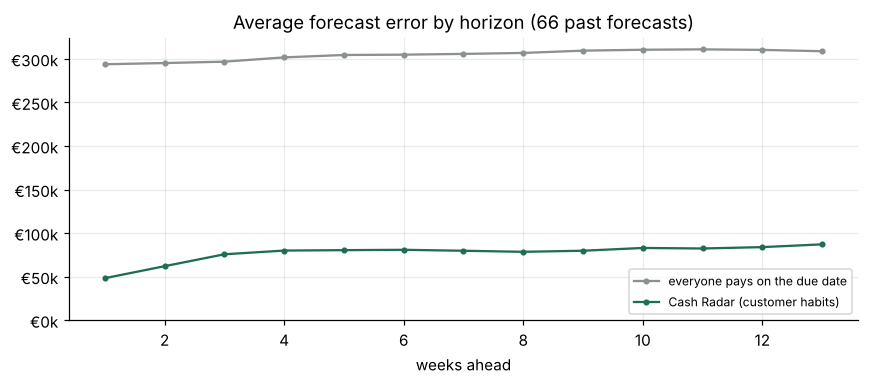

In [14]:
byh = bt.groupby("weeks_ahead")[["error", "error_naive"]].agg(lambda e: e.abs().mean())
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(byh.index, byh.error_naive, "-o", color=GREY, ms=3, label="everyone pays on the due date")
ax.plot(byh.index, byh.error, "-o", color=GREEN, ms=3, label="Cash Radar (customer habits)")
ax.set_xlabel("weeks ahead"); ax.yaxis.set_major_formatter(kfmt); ax.set_ylim(0)
ax.set_title("Average forecast error by horizon (66 past forecasts)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "backtest_error.png", bbox_inches="tight"); plt.show()

## 8. Conclusions and limitations

- **Result:** using each customer's own payment habit cuts the average weekly forecast error by about 75% compared with
  assuming on-time payment, and it would have flagged the October 2025 dip 12 weeks ahead (the naive forecast never did).
- **Warning:** if Lumen pays 45 days late, cash breaks the €100k minimum in week 8 with **7 weeks of warning**,
  while the quarter is still profitable.
- **Limitations:** the method is still about €54k too optimistic on average, so the pessimistic end of the range should
  always be shown; it missed the summer 2025 overdraft because only four months of history existed; payments are taken
  as known in the backtest; all data is simulated.
- **Next steps:** spread each invoice over several possible weeks (probability-weighted timing, ~14% more accurate in
  tests), learn seasonality, and test on real client data in a pilot.